In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os
import glob
import itertools

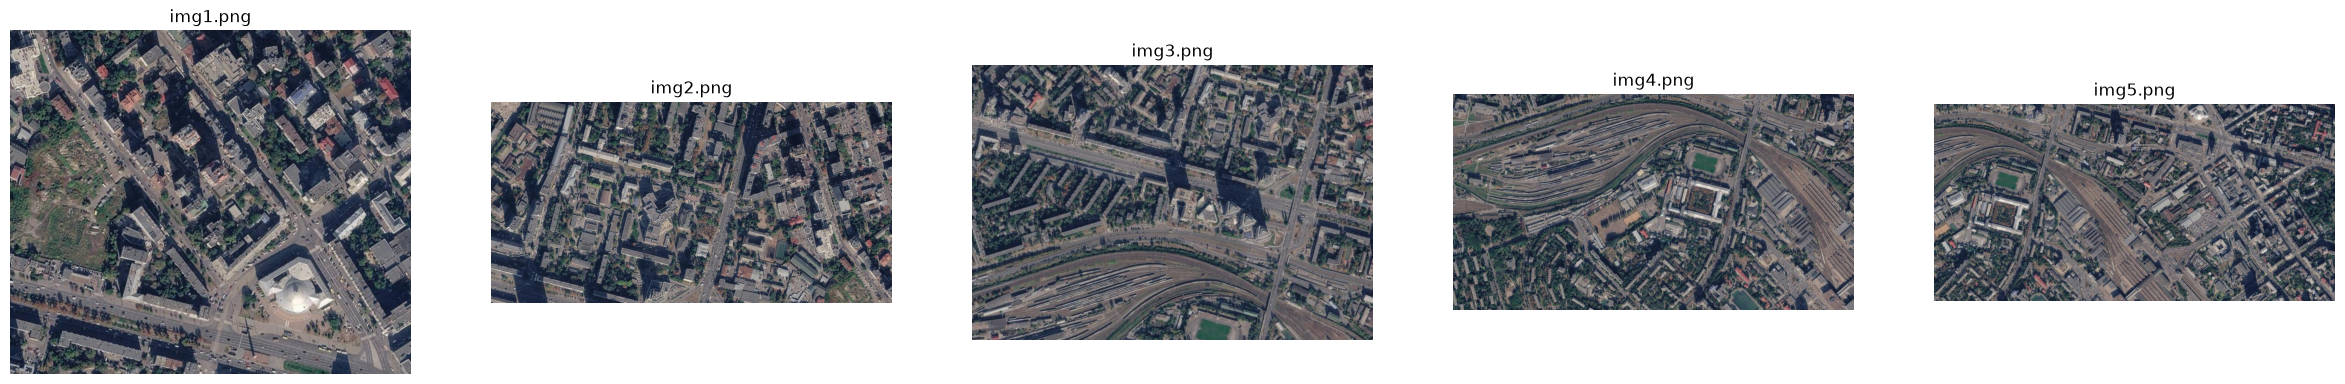

In [2]:
files = sorted(glob.glob("src/satellite/*.png"))
names = [os.path.basename(f) for f in files]
imgs = [cv2.cvtColor(cv2.imread(i), cv2.COLOR_BGR2RGB) for i in files]

fig, ax = plt.subplots(nrows=1, ncols=5, figsize=(30, 20))
for i in range (len(imgs)):
    ax[i].imshow(imgs[i])
    ax[i].axis("off")
    ax[i].set_title(names[i])
plt.show()

In [ ]:
sift = cv2.SIFT_create()
kp, des = zip(*[sift.detectAndCompute(cv2.cvtColor(i, cv2.COLOR_RGB2GRAY), None) for i in imgs])
bf = cv2.BFMatcher(cv2.NORM_L2)
N = len(imgs)

H_pair, W = {}, np.zeros((N, N), int)
for i, j in itertools.combinations(range(N), 2):
    good = [m for m, n in bf.knnMatch(des[j], des[i], k=2) if m.distance < 0.75 * n.distance]
    if len(good) < 10:
        continue
    src = np.float32([kp[j][m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp[i][m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 4.0, maxIters=5000)
    if H is None or mask.sum() < 20:
        continue
    W[i, j] = W[j, i] = int(mask.sum())
    H_pair[(i, j)] = H
    H_pair[(j, i)] = np.linalg.inv(H)

print(f"overlapping pairs: {len(H_pair)//2} of {N*(N-1)//2}")

overlapping pairs: 7 of 10


In [4]:
root = int(W.sum(1).argmax())
in_tree, parent, tree_edges = {root}, {root: None}, []
while len(in_tree) < N:
    a, b = max(((a, b) for a in in_tree for b in range(N)
                if b not in in_tree and W[a, b] > 0), key=lambda e: W[e[0], e[1]])
    in_tree.add(b); parent[b] = a; tree_edges.append((a, b))

H_ref = {root: np.eye(3)}
def to_ref(j):
    if j not in H_ref:
        H_ref[j] = to_ref(parent[j]) @ H_pair[(parent[j], j)]
    return H_ref[j]
for j in range(N):
    to_ref(j)

ANCHOR = names.index("img3.png")
B = np.linalg.inv(H_ref[ANCHOR])
H_ref = {j: B @ H_ref[j] for j in range(N)}

# How much each image is magnified into the shared frame. You need this in Part 4.
scales = [float(np.sqrt(abs(np.linalg.det(H_ref[j][:2, :2])))) for j in range(N)]

print(f"root: {names[root]}, frame anchored on {names[ANCHOR]}\n")
for j in range(N):
    print(f"{names[j]:14s} scale {scales[j]:5.2f}  "
          f"({'downscaled, sharp' if scales[j] < 1 else 'native' if scales[j] == 1 else 'upscaled, soft'})")

root: img4.png, frame anchored on img3.png

img1.png       scale  0.50  (downscaled, sharp)
img2.png       scale  0.50  (downscaled, sharp)
img3.png       scale  1.00  (native)
img4.png       scale  1.00  (downscaled, sharp)
img5.png       scale  1.00  (downscaled, sharp)


In [5]:
def transform_points(H, pts):
    pts = np.asarray(pts, dtype=float).reshape(-1, 2)
    third = np.ones((pts.shape[0], 1), dtype=float)
    res = np.hstack((pts, third))
    res = (H @ res.T).T 
    return res[:, 0:2] / res[:, 2][:, None]

In [6]:
# TEST
rng = np.random.default_rng(0)
pts = rng.uniform(0, 500, size=(200, 2))
mine = transform_points(H_ref[2], pts)
ref = cv2.perspectiveTransform(pts.reshape(-1, 1, 2).astype(np.float32),
                               H_ref[2].astype(np.float32)).reshape(-1, 2)
err = np.abs(mine - ref).max()
print(f"max difference vs OpenCV: {err:.3e}")
assert err < 1e-3, "transform_points is wrong"
print("PASS")

max difference vs OpenCV: 1.517e-05
PASS


In [7]:
def canvas_bounds(imgs, H_ref):
    corners = transform_points(H_ref[0], 
                                [[0, 0], [imgs[0].shape[1], 0], [imgs[0].shape[1], imgs[0].shape[0]], [0, imgs[0].shape[0]]]
                                )
    for i in range(1, len(imgs)):
        corners = np.vstack((corners, transform_points(H_ref[i], 
                                             [[0, 0], [imgs[i].shape[1], 0], [imgs[i].shape[1], imgs[i].shape[0]], [0, imgs[i].shape[0]]]
                                             )))
    x_min, y_min = np.floor(corners.min(axis=0)).astype(int)
    x_max, y_max = np.ceil(corners.max(axis=0)).astype(int)
    T = np.array([
        [1, 0, -x_min],
        [0, 1, -y_min],
        [0, 0, 1]
    ])
    size = (x_max - x_min, y_max - y_min)
    corners = transform_points(T, corners)
    return size, T, corners

In [8]:
# TEST
size, T, corners = canvas_bounds(imgs, H_ref)
print(f"canvas: {size[0]} x {size[1]}  ({size[0]*size[1]/1e6:.1f} MP)")

flat = np.vstack(corners)
assert flat.min() > -1.5 and flat[:, 0].max() < size[0] + 1.5 and flat[:, 1].max() < size[1] + 1.5, \
    "corners should sit inside the canvas after the T shift"
print("PASS")

canvas: 3188 x 1888  (6.0 MP)
PASS


In [9]:
def warp(img, M, size):
    u, v = np.meshgrid(np.arange(0, size[0]), np.arange(0, size[1]))
    uv = np.hstack((u.ravel()[:, None], v.ravel()[:, None]))
    M_inv = np.linalg.inv(M)
    xy = transform_points(M_inv, uv)
    h, w = img.shape[:2]
    mask = ( ( (xy[:, 0] < w - 1) & (xy[:, 0] >= 0) ) & ( (xy[:, 1] < h - 1) & (xy[:, 1] >= 0) ) )
    x = np.floor(xy[mask][:, 0]).astype(int)
    y = np.floor(xy[mask][:, 1]).astype(int)
    dx = xy[mask][:, 0] - x
    dy = xy[mask][:, 1] - y
    if img.ndim == 2:
        sampled = (
            (1 - dx) * (1 - dy) * img[y, x] +
            dx * (1 - dy) * img[y, x + 1] +
            dx * dy * img[y + 1, x + 1] + 
            (1 - dx) * dy * img[y + 1, x]
        )
    if img.ndim == 3:
        sampled = (
            (1 - dx)[:, None] * (1 - dy)[:, None] * img[y, x] +
            dx[:, None] * (1 - dy)[:, None] * img[y, x + 1] +
            dx[:, None] * dy[:, None] * img[y + 1, x + 1] + 
            (1 - dx)[:, None] * dy[:, None] * img[y + 1, x]
        )
    out = np.zeros((size[0] * size[1], *img.shape[2:]), dtype=float)
    out[mask] = sampled
    return out.reshape(size[1], size[0], *img.shape[2:]), mask.reshape(size[1], size[0])

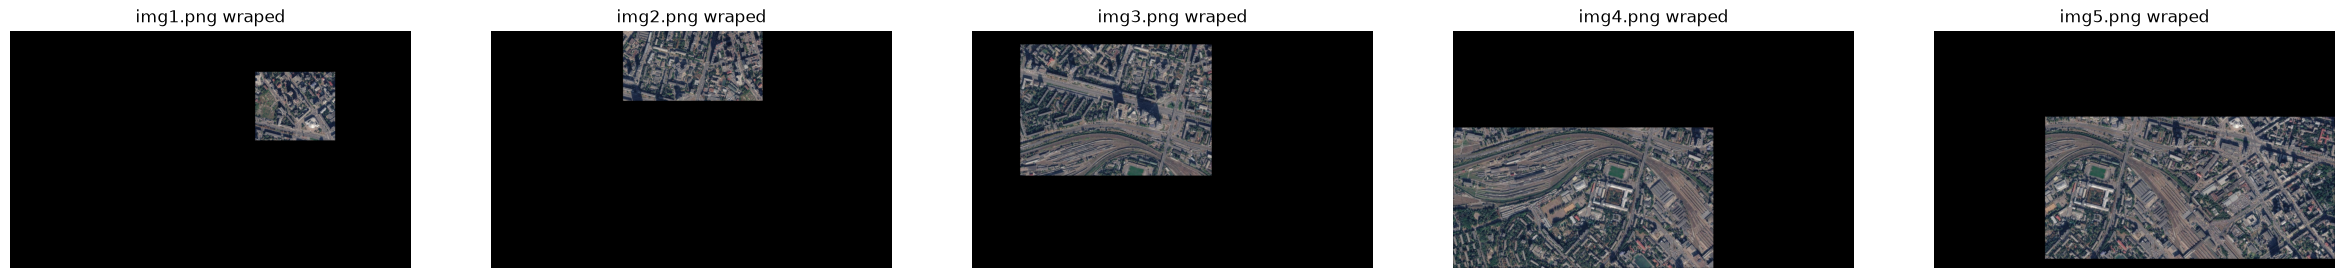

In [10]:
fig, ax = plt.subplots(nrows=1, ncols=5, figsize=(30, 20))
for i in range(len(imgs)):
    img, _ = warp(imgs[i], T @ H_ref[i], size)
    ax[i].imshow(img.astype(np.uint8))
    ax[i].axis("off")
    ax[i].set_title(f"{names[i]} wraped")
plt.show()

In [11]:
def feather_weight(h, w):
    x, y = np.meshgrid(np.arange(w), np.arange(h))
    d = np.minimum.reduce([x, y, w - 1 - x, h - 1 - y])
    m = d.max()
    return d / m if m > 0 else d.astype(float)

PASS


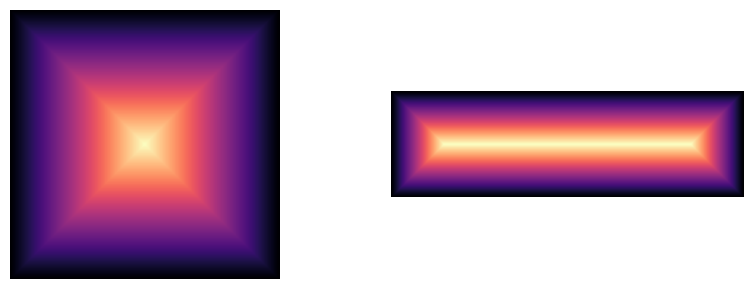

In [12]:
# TEST
fw = feather_weight(100, 200)
assert fw.shape == (100, 200), "wrong shape"
assert abs(fw.max() - 1.0) < 1e-6, "centre should be 1.0"
assert fw[0].max() == 0 and fw[-1].max() == 0 and fw[:, 0].max() == 0 and fw[:, -1].max() == 0, \
    "border must be 0"
assert fw[50, 100] > fw[10, 100] > fw[1, 100], "should increase away from the edge"
print("PASS")
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 3.5))
ax[0].imshow(feather_weight(300, 300), cmap="magma")
ax[0].axis("off")
ax[1].imshow(feather_weight(120, 400), cmap="magma")
ax[1].axis("off")
plt.show()

img1.png       covers   5.8% of canvas, max weight 2.00
img2.png       covers  10.3% of canvas, max weight 2.00
img3.png       covers  26.4% of canvas, max weight 1.00
img4.png       covers  38.4% of canvas, max weight 1.00
img5.png       covers  43.3% of canvas, max weight 1.00


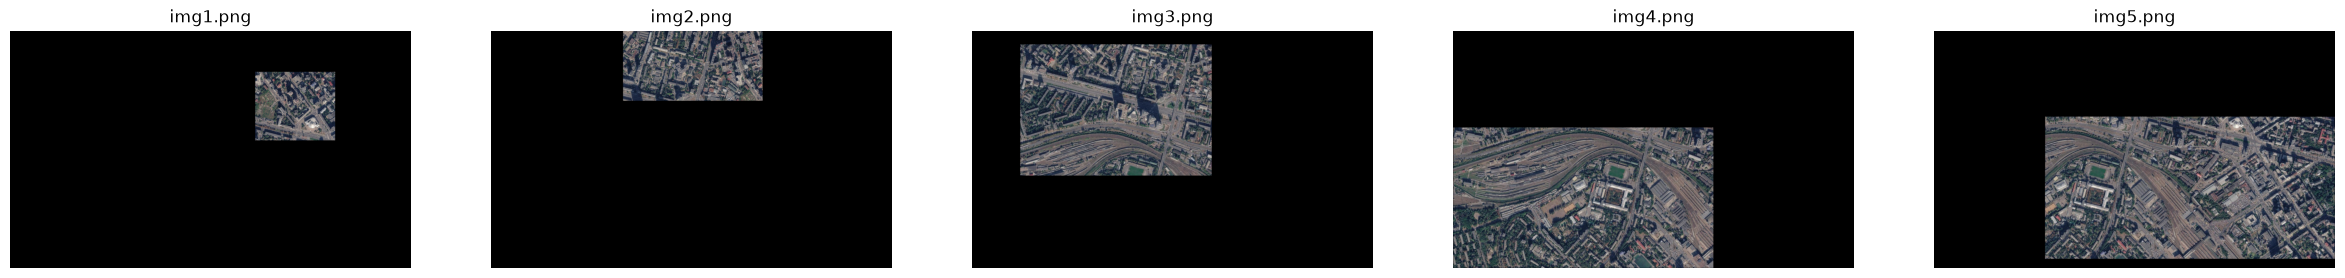

In [13]:
warps, weights = [], []
for j in range(N):
    M = T @ H_ref[j]
    h, w = imgs[j].shape[:2]
    wimg, inside = warp(imgs[j], M, size)
    wfw, _ = warp(feather_weight(h, w), M, size)
    weight = (np.clip(wfw, 0, 1) ** 2) / scales[j]
    weight[~inside] = 0.0
    warps.append(wimg)
    weights.append(weight)
    print(f"{names[j]:14s} covers {100*inside.mean():5.1f}% of canvas, "
          f"max weight {weight.max():.2f}")
fig, ax = plt.subplots(nrows=1, ncols=5, figsize=(30, 20))
for i in range(5):
    ax[i].imshow(warps[i].astype(np.uint8))
    ax[i].axis("off")
    ax[i].set_title(names[i])
plt.show()

In [14]:
def stitch(warps, weights, size):
    weights_array = np.asarray(weights, dtype=float)
    warps_array = np.asarray(warps, dtype=float)
    num = np.sum(weights_array[..., None] * warps_array, axis=0)
    den = np.sum(weights_array, axis=0)
    covered = den > 0
    mosaic = np.zeros((size[1], size[0], 3), dtype=np.uint8)
    mosaic[covered] = np.clip(num[covered] / den[covered, None], 0, 255).astype(np.uint8)
    return mosaic, covered

In [15]:
# TEST
a = np.full((4, 4, 3), 100.0, np.float32)
b = np.full((4, 4, 3), 200.0, np.float32)
m, cov = stitch([a, b], [np.full((4, 4), 1.0, np.float32),
                         np.full((4, 4), 3.0, np.float32)], (4, 4))
assert cov.all(), "everything was covered here"
assert abs(int(m[0, 0, 0]) - 175) <= 1, f"expected (100*1 + 200*3)/4 = 175, got {m[0,0,0]}"

m2, cov2 = stitch([a], [np.zeros((4, 4), np.float32)], (4, 4))
assert not cov2.any() and (m2 == 0).all(), "zero weight must mean uncovered and black"
print("PASS")

PASS


canvas coverage: 83.2%   (black = no image)


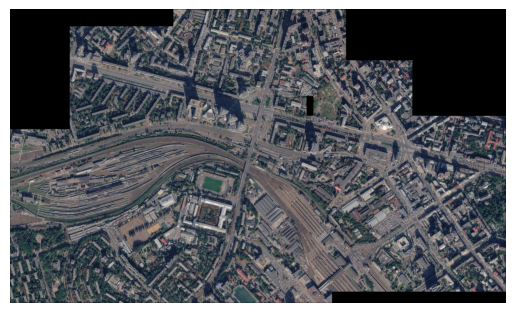

In [16]:
mosaic, covered = stitch(warps, weights, size)
print(f"canvas coverage: {100*covered.mean():.1f}%   (black = no image)")

os.makedirs("outputs", exist_ok=True)
plt.imsave("outputs/lab_satellite.png", mosaic)
plt.imshow(mosaic)
plt.axis("off")
plt.show()